# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

### Phương pháp Naive – O(n²)

Hàm `conflicts_naive(board)` tính tổng số cặp quân hậu tấn công nhau bằng cách:

- Đếm số quân hậu trên từng hàng và tính số cặp xung đột.
- Duyệt qua từng quân hậu, kiểm tra các quân bên phải có nằm trên cùng đường chéo hay không.
- Cộng tất cả xung đột để thu được giá trị hàm mục tiêu.

Do sử dụng các vòng lặp lồng nhau để kiểm tra các cặp quân hậu, độ phức tạp thời gian của thuật toán là O(n²).

Phương pháp này đơn giản nhưng chi phí tính toán tăng nhanh khi kích thước bàn cờ lớn.

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

### Phương pháp Linear – O(n)

Thay vì kiểm tra từng cặp quân hậu, hàm `conflicts(board)` sử dụng ba mảng để đếm số quân hậu nằm trên cùng hàng và hai hướng đường chéo.

Với mỗi quân hậu tại cột i, hàng board[i]:

- Hàng được xác định bởi `board[i]`.
- Đường chéo thứ nhất được xác định bởi `i + board[i]`.
- Đường chéo thứ hai được xác định bởi `i - board[i] + n`.

Sau khi đếm số quân hậu trên từng hàng và đường chéo, thuật toán cộng số cặp xung đột để tính hàm mục tiêu.

Do mỗi quân hậu chỉ cần được duyệt một lần và tổng số phần tử trong các mảng đếm tỉ lệ với n, độ phức tạp thời gian là O(n). Phương pháp này sử dụng thêm O(n) bộ nhớ.

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

### Phương pháp JIT Numba – O(n)

Hàm `conflicts_jit(board)` sử dụng nguyên lý đếm xung đột theo hàng và đường chéo tương tự phương pháp Linear.

Điểm khác biệt là hàm được trang trí bằng `@njit()` của Numba để biên dịch mã Python thành mã máy khi thực thi lần đầu với kiểu dữ liệu đầu vào tương ứng.

Việc biên dịch giúp giảm chi phí thực thi vòng lặp và các thao tác tính toán, từ đó có thể cải thiện hiệu năng.

Tuy nhiên, Numba không thay đổi độ phức tạp tiệm cận của thuật toán. Cả Linear và JIT đều có độ phức tạp O(n), nhưng thời gian thực thi thực tế có thể khác nhau đáng kể.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

### Kiểm tra tính chính xác của các hàm đếm xung đột

Trước khi so sánh hiệu năng, cần kiểm tra xem ba phương pháp `conflicts_naive()`, `conflicts()` và `conflicts_jit()` có cho cùng kết quả hay không.

Thí nghiệm sử dụng các bàn cờ n-Queens với kích thước khác nhau, bao gồm một cấu hình có nghiệm hợp lệ và các cấu hình ngẫu nhiên. Nếu cả ba hàm trả về cùng số xung đột, ta có cơ sở để so sánh thời gian thực thi của chúng.

In [5]:
test_boards = [
    np.array([1, 3, 0, 2]),
    np.array([0, 1, 2, 3]),
    np.random.default_rng(42).integers(0, 8, size=8),
    np.random.default_rng(42).integers(0, 20, size=20)
]

for board in test_boards:
    naive = conflicts_naive(board)
    linear = conflicts(board)
    jit = conflicts_jit(board)

    print(f"Board: {board}")
    print(f"Naive: {naive}, Linear: {linear}, JIT: {jit}")
    print(f"Consistent: {naive == linear == jit}")
    print("-" * 50)

    assert naive == linear == jit

print("All tests passed!")

Board: [1 3 0 2]
Naive: 0, Linear: 0, JIT: 0
Consistent: True
--------------------------------------------------
Board: [0 1 2 3]
Naive: 6, Linear: 6, JIT: 6
Consistent: True
--------------------------------------------------
Board: [0 6 5 3 3 6 0 5]
Naive: 9, Linear: 9, JIT: 9
Consistent: True
--------------------------------------------------
Board: [ 1 15 13  8  8 17  1 13  4  1 10 19 14 15 14 15 10  2 16  9]
Naive: 21, Linear: 21, JIT: 21
Consistent: True
--------------------------------------------------
All tests passed!


# Compare Timing

Compare runtime on 20 random boards of different sizes.

In [6]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

### Chuẩn bị và đo thời gian thực thi

Trước khi đo, `conflicts_jit(random_board(4))` được gọi để kích hoạt biên dịch JIT cho kiểu đầu vào NumPy nguyên tương ứng; nhờ vậy phép đo chủ yếu phản ánh thời gian thực thi sau biên dịch, thay vì chi phí biên dịch lần đầu. Với mỗi kích thước, tổng thời gian xử lý 20 bàn cờ được chia cho 20 và đổi sang microsecond (µs) trên mỗi bàn cờ.

Các mảng `x`, `naive_times`, `linear_times` và `jit_times` lưu kích thước bàn cờ và thời gian trung bình, dùng cho bảng số liệu và hai biểu đồ phía sau. Đây là phép đo một lượt trên mỗi tập 20 bàn cờ, nên thời gian có thể dao động nếu chạy lại.

In [7]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 49.649999709799886, linear: 11.154999810969457, jit: 1.080000220099464


### Bảng thời gian thực thi

Thực hiện đo thời gian trung bình của ba phương pháp trên nhiều kích thước bàn cờ n-Queens.

Mỗi kích thước sử dụng 20 bàn cờ ngẫu nhiên với cùng tập dữ liệu đầu vào cho cả ba hàm. Hàm JIT được gọi trước khi đo để tránh tính thời gian biên dịch lần đầu vào kết quả.

Thời gian được biểu diễn bằng microsecond (µs) trên mỗi bàn cờ.

In [8]:
import pandas as pd

df_times = pd.DataFrame({
    "Board Size (n)": x,
    "Naive (µs)": naive_times,
    "Linear (µs)": linear_times,
    "JIT (µs)": jit_times
})

print(df_times.round(3).to_string(index=False))


 Board Size (n)  Naive (µs)  Linear (µs)  JIT (µs)
              8      49.650       11.155     1.080
             50     727.655       78.220     2.065
            100    2179.800      131.850     4.145
            150    4459.445      323.525     5.330
            200    9410.765      230.070     3.725
            250   14109.055      490.355     7.470
            300   21846.960      538.825    27.475
            350   26772.770      517.995     7.595
            400   35443.170      600.685     6.770
            450   39361.945      802.295    12.015


### Biểu đồ 1 – So sánh thời gian của cả ba phương pháp

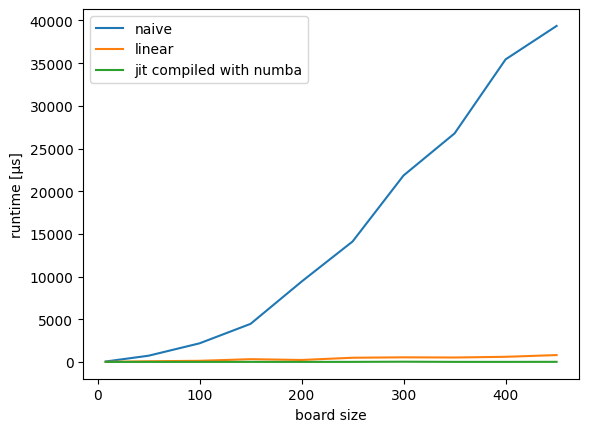

In [9]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [µs]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

### Nhận xét

Kết quả thí nghiệm cho thấy sự khác biệt về thời gian thực thi giữa ba phương pháp ngày càng rõ rệt khi kích thước bàn cờ tăng.

Tại n=8, thời gian trung bình của Naive là 49.650 µs, Linear là 11.155 µs và JIT Numba là 1.080 µs.

Khi tăng lên n=450, thời gian của Naive đạt 39361.945 µs, trong khi Linear là 802.295 µs và JIT chỉ mất 12.015 µs.

Điều này cho thấy phương pháp Naive có thời gian tăng nhanh theo kích thước bài toán, phù hợp với độ phức tạp O(n²). Ngược lại, Linear và JIT có độ phức tạp O(n), giúp giảm đáng kể chi phí tính toán.

Nhìn chung, tối ưu thuật toán từ O(n²) xuống O(n) mang lại lợi ích lớn khi kích thước bàn cờ tăng. Việc sử dụng Numba còn giúp cải thiện tốc độ thực thi mà không làm thay đổi độ phức tạp tiệm cận của thuật toán.

### Biểu đồ 2 – So sánh riêng Linear và JIT Numba

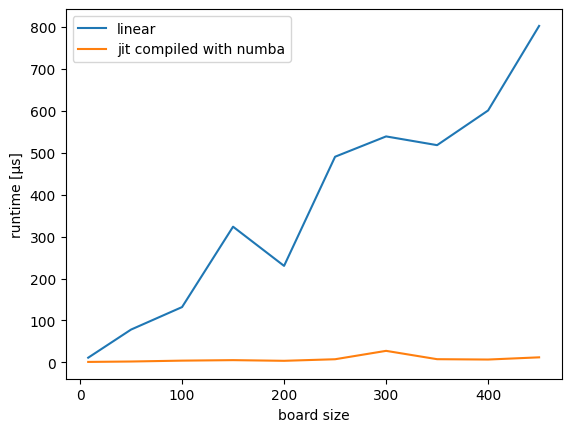

In [10]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [µs]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

### Nhận xét biểu đồ so sánh Linear và JIT Numba

Biểu đồ tập trung so sánh hai phương pháp có cùng độ phức tạp thời gian O(n).

Mặc dù cùng sử dụng nguyên lý đếm xung đột theo hàng và đường chéo, JIT Numba có thể thực thi nhanh hơn nhờ biên dịch các vòng lặp tính toán thành mã máy.

Với bàn cờ n=8, thời gian trung bình của Linear là 11.155 µs, trong khi JIT Numba là 1.080 µs, tương ứng JIT nhanh hơn trong lần đo này.

Sự khác biệt cho thấy độ phức tạp thuật toán không phải yếu tố duy nhất quyết định tốc độ thực thi. Ngôn ngữ lập trình, chi phí xử lý vòng lặp và cơ chế biên dịch cũng ảnh hưởng đến hiệu năng thực tế.

Tuy nhiên, tốc độ tăng thêm từ JIT có thể thay đổi theo kích thước dữ liệu và môi trường chạy.